# REI scoring demo (synthetic data)

This notebook shows **how** the REI scoring framework ranks land parcels near upcoming infrastructure.

Everything here is synthetic: the projects, parcels, prices and factor weights are made up for illustration. The production version runs on public Indian government and market data with calibrated weights, which are not published.

The idea: land prices tend to move when a credible infrastructure project (metro line, highway, airport) gets close to construction. Parcels that are near a **credible** project, **early** in its timeline, and still **priced below** comparable land have the most room to re-rate.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams["text.parse_math"] = False

rng = np.random.default_rng(7)
pd.set_option("display.precision", 2)

## 1. Infrastructure projects

Each project gets a **credibility** score from public signals: who sponsors it, whether funding is sanctioned, whether environmental clearance is granted, and whether land acquisition has started. A project that looks exciting on paper but has none of these is treated as noise.

**Timing** captures how early we are. The most upside sits between approval and the start of construction, before the market fully prices it in.

In [2]:
projects = pd.DataFrame({
    "project": ["Metro Line A", "Expressway B", "Airport C", "Ring Road D", "Metro Line E (stalled)"],
    "x_km": [4.0, 15.0, 22.0, 9.0, 18.0],
    "y_km": [6.0, 4.0, 17.0, 16.0, 9.0],
    "sponsor_govt": [1, 1, 1, 0, 1],          # central / state body vs private announcement
    "funding_sanctioned": [1, 1, 0, 0, 0],
    "env_clearance": [1, 1, 1, 0, 0],
    "land_acquisition_started": [1, 0, 0, 0, 0],
    "stage": ["approved", "approved", "announced", "announced", "stalled"],
})

signals = ["sponsor_govt", "funding_sanctioned", "env_clearance", "land_acquisition_started"]
projects["credibility"] = projects[signals].mean(axis=1)

# Timing: most upside between approval and construction start
timing_map = {"announced": 0.5, "approved": 1.0, "under_construction": 0.6, "completed": 0.1, "stalled": 0.0}
projects["timing"] = projects["stage"].map(timing_map)
projects[["project", "stage", "credibility", "timing"]]

,project,stage,credibility,timing
0,Metro Line A,approved,1.00,1.0
1,Expressway B,approved,0.75,1.0
2,Airport C,announced,0.50,0.5
3,Ring Road D,announced,0.00,0.5
4,Metro Line E (stalled),stalled,0.25,0.0


## 2. Parcels

Synthetic parcels scattered across a 25 x 20 km area, each with an asking price per sq ft. **Headroom** compares the parcel's price with a local benchmark (here, the median of its 10 nearest neighbours). A parcel priced below its neighbourhood has more room to re-rate.

In [3]:
n = 400
parcels = pd.DataFrame({
    "parcel_id": [f"P{i:03d}" for i in range(n)],
    "x_km": rng.uniform(0, 25, n),
    "y_km": rng.uniform(0, 20, n),
})
# Base price rises toward a city centre at (5, 5), plus noise
dist_centre = np.hypot(parcels.x_km - 5, parcels.y_km - 5)
parcels["price_psf"] = (6000 * np.exp(-dist_centre / 12) * rng.lognormal(0, 0.25, n)).round(0)

# Local benchmark: median price of the 10 nearest parcels
xy = parcels[["x_km", "y_km"]].to_numpy()
d = np.hypot(xy[:, None, 0] - xy[None, :, 0], xy[:, None, 1] - xy[None, :, 1])
nearest = np.argsort(d, axis=1)[:, 1:11]
parcels["benchmark_psf"] = np.median(parcels.price_psf.to_numpy()[nearest], axis=1)
parcels["headroom"] = (1 - parcels.price_psf / parcels.benchmark_psf).clip(-0.5, 0.5)
parcels.head()

,parcel_id,x_km,y_km,price_psf,benchmark_psf,headroom
0,P000,15.63,6.59,1458.0,2190.5,0.33
1,P001,22.43,18.73,861.0,961.0,0.10
2,P002,19.39,3.10,1231.0,1912.0,0.36
3,P003,5.63,10.29,3273.0,3342.0,0.02
4,P004,7.50,1.83,4702.0,4252.0,-0.11


## 3. Proximity with distance decay

Impact fades with distance from a project. A simple exponential decay gives a parcel 1.0 at the project and about 0.37 at the decay length (illustrative: 3 km).

Projects below a minimum credibility are dropped **before** matching, so a parcel can never borrow upside from an announcement that is unlikely to be built. Each parcel is then matched to the credible project with the strongest pull on it.

In [4]:
DECAY_KM = 3.0          # illustrative
CREDIBILITY_GATE = 0.5  # illustrative

px = projects[["x_km", "y_km"]].to_numpy()
dist = np.hypot(xy[:, None, 0] - px[None, :, 0], xy[:, None, 1] - px[None, :, 1])  # parcels x projects
proximity = np.exp(-dist / DECAY_KM)

eligible = (projects.credibility >= CREDIBILITY_GATE).to_numpy()
pull = proximity * (projects.credibility * projects.timing).to_numpy() * eligible

best = pull.argmax(axis=1)
rows = np.arange(n)
parcels["nearest_catalyst"] = projects.project.to_numpy()[best]
parcels["distance_km"] = dist[rows, best]
parcels["proximity"] = proximity[rows, best] * eligible[best]
parcels["credibility"] = projects.credibility.to_numpy()[best]
parcels["timing"] = projects.timing.to_numpy()[best]
print("Projects passing the credibility gate:", list(projects.project[eligible]))

Projects passing the credibility gate: ['Metro Line A', 'Expressway B', 'Airport C']


## 4. Combined score

Proximity acts as a multiplier: if no credible project reaches a parcel, nothing else can rescue its score. Credibility, timing and headroom are weighted inside it, giving a score from 0 to 100.

**The weights below are placeholders for the demo**, not the calibrated production weights.

In [5]:
WEIGHTS = {"credibility": 0.35, "timing": 0.35, "headroom": 0.30}  # illustrative only

parcels["headroom_scaled"] = parcels.headroom + 0.5  # map -0.5..0.5 to 0..1
parcels["score"] = 100 * parcels.proximity * (
    WEIGHTS["credibility"] * parcels.credibility
    + WEIGHTS["timing"] * parcels.timing
    + WEIGHTS["headroom"] * parcels.headroom_scaled
)

shortlist = (parcels.sort_values("score", ascending=False)
             .head(10)[["parcel_id", "nearest_catalyst", "distance_km", "price_psf",
                        "benchmark_psf", "headroom", "score"]])
shortlist

,parcel_id,nearest_catalyst,distance_km,price_psf,benchmark_psf,headroom,score
355,P355,Metro Line A,0.51,4597.0,5179.5,0.11,74.52
128,P128,Metro Line A,0.53,4690.0,5179.5,0.09,73.57
194,P194,Metro Line A,0.73,4073.0,4804.5,0.15,70.22
290,P290,Metro Line A,0.94,3895.0,4335.0,0.10,64.27
329,P329,Metro Line A,0.77,4958.0,4643.5,-0.07,64.13
63,P063,Metro Line A,0.79,4919.0,4566.0,-0.08,63.44
154,P154,Expressway B,0.91,2184.0,2927.0,0.25,61.96
166,P166,Expressway B,0.35,3457.0,2808.5,-0.23,61.79
44,P044,Expressway B,0.99,1858.0,2667.0,0.30,61.28
80,P080,Metro Line A,0.82,6053.0,4938.5,-0.23,59.42


## 5. Map of the result

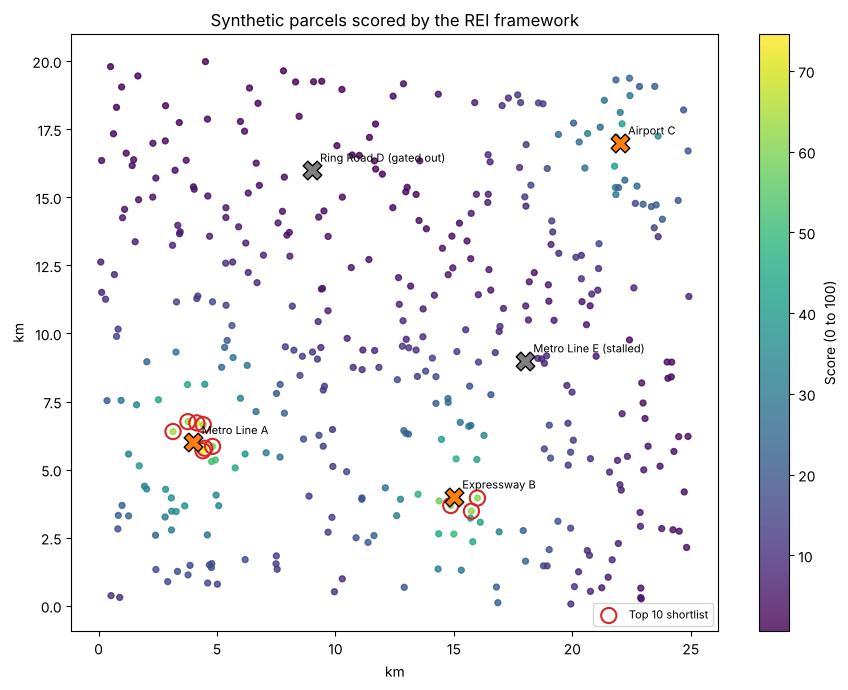

In [6]:
fig, ax = plt.subplots(figsize=(9, 7))
sc = ax.scatter(parcels.x_km, parcels.y_km, c=parcels.score, cmap="viridis", s=18, alpha=0.8)
top = parcels.loc[shortlist.index]
ax.scatter(top.x_km, top.y_km, facecolors="none", edgecolors="#d62728", s=120, lw=1.5, label="Top 10 shortlist")
for _, p in projects.iterrows():
    gated = p.credibility < CREDIBILITY_GATE
    ax.scatter(p.x_km, p.y_km, marker="X", s=180, color="#7f7f7f" if gated else "#ff7f0e",
               edgecolors="black", zorder=3)
    ax.annotate(p.project + (" (gated out)" if gated and "stalled" not in p.project else ""), (p.x_km, p.y_km), xytext=(6, 6), textcoords="offset points", fontsize=8)
plt.colorbar(sc, label="Score (0 to 100)")
ax.set(xlabel="km", ylabel="km", title="Synthetic parcels scored by the REI framework")
ax.legend(loc="lower right", fontsize=8)
plt.tight_layout()
plt.savefig("images/scoring_map.png", dpi=130)
plt.show()

## 6. Sanity check: the stalled project

Metro Line E sits in the middle of the map, but it has no sanctioned funding, no clearance and is stalled. Parcels around it should score near zero no matter how close they are or how cheap they look. That is the main failure the framework is built to avoid: buying into announcements that never get built.

In [7]:
near_e = parcels[np.hypot(parcels.x_km - 18, parcels.y_km - 9) < 2]
print(f"Parcels within 2 km of Metro Line E: {len(near_e)}")
print(f"Their median score: {near_e.score.median():.1f}")
print(f"Median score of the top 10 shortlist: {shortlist.score.median():.1f}")
print("Best catalyst assigned to them:", near_e.nearest_catalyst.value_counts().to_dict())
print(f"Median distance to that catalyst: {near_e.distance_km.median():.1f} km")

Parcels within 2 km of Metro Line E: 12
Their median score: 9.0
Median score of the top 10 shortlist: 63.8
Best catalyst assigned to them: {'Expressway B': 12}
Median distance to that catalyst: 6.3 km


## What the production version adds

- Real project data from public sources (central and state infrastructure authorities, environmental clearance records, RERA registrations)
- Declared vs actual transaction prices as a second signal for mispricing
- Weights calibrated by backtesting against historical projects, including ones that stalled or failed
- Spatial joins in PostGIS instead of the brute-force distance matrix used here